In [ ]:
from typing import List
import os

metrics = [
    "top-k-retrieval-accuracy",
    "recall@k",
    "precision@k",
    "hit-rate",
    "mrr"
]

def benchmark(results: List):
    pass

def write_logs(file_path: str, retriever: str, metrics: dict, timestamp='unknown timestamp'):
    # It's easier to ask for forgiveness than for permission
    with open(file_path, 'a') as log:
        log.write(f'{timestamp}    {retriever}: \n ')
        for metric_name, metric_value in metrics.items():

            log.write(f'      {metric_name:<10} {metric_value}\n')
        log.write('\n')
    

def recall_count(results: List, expected_results: List):
    return len(set(results) & set(expected_results)) / len(expected_results)


def precision_count(results: List, expected_results: List):
    return len(set(results) & set(expected_results)) / len(results)

def hit_rate():
    pass

def reciprocal_rank(y: List[int], y_pred: List[int]):
        if not y or len(y) < 1:
            return 0
        most_relevant_chunk = y_pred[0]
        for idx, val in enumerate(y):
            if val == most_relevant_chunk:
                return 1 / (idx+1)
        return 0

def mean_reciprocal_rank(results: List, expected_results: List):
    rr = [reciprocal_rank(result, expected_result) for result, expected_result in zip(results, expected_results)]
    return sum(rr) / len(rr)

def average_precision(result, expected_results):
    relevant = 0
    precisions = []
    for i, p in enumerate(expected_results):
        if p in result:
            relevant += 1
            precisions.append(relevant / (i + 1))
    if not precisions:
        return 0
    return sum(precisions) / len(result)

def mean_average_precision(results, expected_results):
    ap = [average_precision(res, exp) for res, exp in zip(results, expected_results)]
    return sum(ap) / len(ap)

    

In [2]:

results = ['a', 'b', 'c']
expected_results = ['c', 'd', 'f', 'e']

list_results =  [[1] , [2], [3]]
list_expected = [[3,2,1], [1,2,3], [3,2,1]]

print(mean_average_precision(list_results, list_expected))

0.611111111111111


/tmp/ipykernel_1348738/202276681.py:63: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


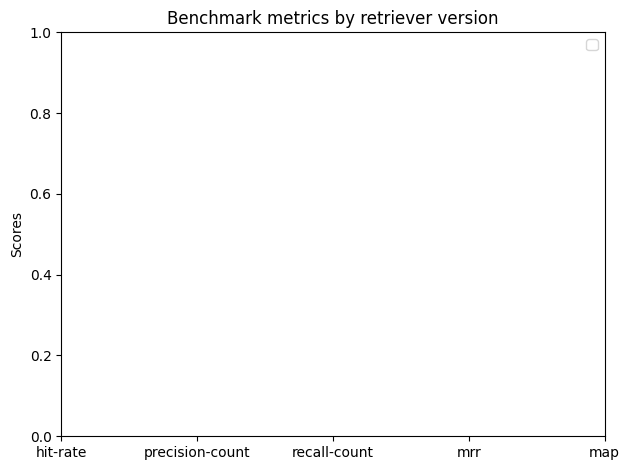

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

METRICS = [
        'hit-rate',
        'precision-count',
        'recall-count',
        'mrr',
        'map'
    ]

def visualize_metrics(retrievers_and_values: dict, metrics: List=METRICS):
    '''
        { "model1": {"metric": 12},
            "model2" : {"metric":32}
        }
    '''
    
    '''
    retrievers_and_values = {
        "model1": {'precision':35,
                    'map': 28},
        "model2": {'precision-count':2,
                    'map': 80},
        "model3": {'precision-count':10,
                    'map': 5},
        "model4": {'precision-count':10,
                    'map': 5},
        "model5": {'precision-count':10,
                    'map': 5},
    }
    '''

    data_groups = []
    labels = []
    for retriever,values in retrievers_and_values.items():
        data_group = []
        for metric in metrics:
            if metric in values:
                data_group.append(values[metric])
            else:
                data_group.append(0.0)
        data_groups.append(data_group)
        labels.append(retriever)


    x = np.arange(len(metrics))
    width = 0.4 

    fig, ax = plt.subplots()
    i = 0.5
    for label, dg in zip(labels, data_groups):
        ax.bar((x-width/2) + (width/len(labels)*i), dg, width=width/len(labels), label=label)
        i+=1


    ax.set_ylabel('Scores')
    ax.set_title('Benchmark metrics by retriever version')
    ax.set_xticks(x)
    ax.set_xticklabels(metrics)
    ax.legend()

    fig.tight_layout()

    plt.show()

test_metrics = {'precision':35,
                    'map': 28}
visualize_metrics({})
write_logs('/home/tchrisp/NeoNova/logs/test', 'model1', test_metrics)
